# Exp D — Detector Cego em Lote Realista

**T. Bandeira · Junho de 2026**
*Série analise-espectral-primos — continuação de Exp Cascata (Nota 37) e Exp Escala (Nota 38)*

---

## Objetivo

Simular um cenário próximo de aplicação real: um lote de 30 candidatos com estrutura
totalmente oculta, contendo grupos de tamanhos distintos compartilhando fatores
diferentes, além de "decoys" (candidatos sem nenhum fator compartilhado). O detector
deve identificar autonomamente todos os grupos, classificar cada candidato, e
fatorar completamente os grupos com cofator composto — sem nenhuma informação prévia
sobre a estrutura.

## Estrutura oculta (não revelada ao algoritmo)

| grupo | tamanho | cofator | tipo |
|---|---|---|---|
| A | 12 | 143 = 11×13 | composto → requer Stage 2 |
| B | 8 | 11 | primo direto |
| C | 6 | 17 | primo direto |
| Decoys | 4 | — ($P_1$-suaves) | sem fator compartilhado |

**Total: 30 candidatos. Comparação: MDC par-a-par = 435 operações vs. 2 FFTs.**


## 1. Setup

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from sympy import isprime, factorint
import pandas as pd
from collections import Counter

T_MAX = 6500.0
DT    = 0.05
W     = 5

t     = np.arange(0.1, T_MAX, DT)
freqs = np.fft.rfftfreq(len(t), d=DT)
print(f'Pontos: {len(t):,}  |  Delta_f = {freqs[1]:.6f}')

BG     = '#0D0D1A'
C_A    = '#A8E6CF'   # verde  — grupo A (composto)
C_B    = '#7EB8F7'   # azul   — grupo B (primo 11)
C_C    = '#DDA0DD'   # lila   — grupo C (primo 17)
C_DEC  = '#445566'   # cinza  — decoys
C_S2   = '#F97B6B'   # vermelho — Stage 2
C_GRID = '#1E1E3A'
C_TEXT = '#CCCCDD'

P1 = [2, 3, 5, 7]

def v_q(m, q):
    v = 0
    while m % q == 0:
        v += 1; m //= q
    return v

def log_res(m, qs):
    lr = math.log(m)
    for q in qs:
        lr -= v_q(m, q) * math.log(q)
    return lr

def cofator(m, qs):
    lr = log_res(m, qs)
    return 1 if lr < 1e-9 else round(math.exp(lr))

def amp_em_f(F, f, w=W):
    idx = np.argmin(np.abs(freqs - f))
    return np.max(F[max(0,idx-w):min(len(F),idx+w)])

def espectro(s):
    return np.abs(np.fft.rfft(s)) * DT

def amp_iso_de(q):
    R = -np.cos(t * math.log(q)) / math.sqrt(math.log(q))
    return amp_em_f(espectro(R), math.log(q)/(2*math.pi))

def sinal_de(candidatos, log_func=None):
    R = np.zeros(len(t))
    for m in candidatos:
        lr = log_res(m, P1) if log_func is None else log_func(m)
        if lr > 1e-9:
            R += -np.cos(t * lr) / math.sqrt(lr)
    return R

print('Setup concluido.')


Pontos: 129,998  |  Delta_f = 0.000154
Setup concluido.


## 2. Geração do lote (estrutura oculta para o algoritmo)

Os candidatos são gerados aqui com estrutura conhecida, mas a partir da próxima célula
o algoritmo só recebe a lista `LOTE` — sem rótulos de grupo, sem fatoração.


In [2]:
# Grupo A: 12 candidatos com cofator 143=11x13 (composto)
SMOOTH_A = [2,3,4,5,6,7,8,9,10,12,14,15,16,18]
GRUPO_A  = sorted([s*143 for s in SMOOTH_A])[:12]

# Grupo B: 8 candidatos com cofator 11 (primo)
GRUPO_B  = [22,33,44,55,66,77,88,99]

# Grupo C: 6 candidatos com cofator 17 (primo)
GRUPO_C  = [34,51,68,85,102,119]

# Decoys: 4 candidatos P1-suaves (sem fator compartilhado, cofator=1)
DECOYS   = [12, 18, 36, 60]

LOTE = GRUPO_A + GRUPO_B + GRUPO_C + DECOYS
LABELS_REAIS = (['A']*len(GRUPO_A) + ['B']*len(GRUPO_B) +
                ['C']*len(GRUPO_C) + ['decoy']*len(DECOYS))

print(f'LOTE apresentado ao algoritmo ({len(LOTE)} candidatos):')
print(LOTE)
print()
print('(estrutura real oculta ate a Secao 6, usada so para verificacao)')


LOTE apresentado ao algoritmo (30 candidatos):
[286, 429, 572, 715, 858, 1001, 1144, 1287, 1430, 1716, 2002, 2145, 22, 33, 44, 55, 66, 77, 88, 99, 34, 51, 68, 85, 102, 119, 12, 18, 36, 60]

(estrutura real oculta ate a Secao 6, usada so para verificacao)


## 3. Stage 1 — varredura cega do espectro residual

O algoritmo constrói o sinal de `LOTE` colapsado pela base $P_1=\{2,3,5,7\}$ e varre
o espectro residual em busca de picos anômalos — sem nenhuma informação sobre quantos
grupos existem ou quais fatores eles compartilham.


In [3]:
print('Construindo sinal Stage 1 do lote completo...')
F1 = espectro(sinal_de(LOTE))

# Varredura as-cegas: testar cada q candidato a cofator no intervalo plausivel
Q_MAX = max(LOTE) // 2 + 1
THRESHOLD = 1.8

achados_s1 = []
for q in range(8, Q_MAX):
    fq = math.log(q) / (2*math.pi)
    a  = amp_em_f(F1, fq)
    ai = amp_iso_de(q)
    ratio = a / ai
    if ratio > THRESHOLD:
        achados_s1.append({'q': q, 'ratio': ratio, 'k_estimado': round(ratio),
                           'primo': isprime(q)})

print(f'Varredura q=8..{Q_MAX}, threshold={THRESHOLD}')
print()
print(f'{"q":>5}  {"ratio":>8}  {"k_estimado":>11}  {"primo":>7}  {"status":>14}')
print('-'*52)
for a in sorted(achados_s1, key=lambda x:-x['ratio']):
    status = 'PRIMO (final)' if a['primo'] else 'COMPOSTO->S2'
    print(f'{a["q"]:>5}  {a["ratio"]:>8.4f}  {a["k_estimado"]:>11}  {str(a["primo"]):>7}  {status:>14}')

print()
print(f'Picos detectados: {len(achados_s1)}')


Construindo sinal Stage 1 do lote completo...
Varredura q=8..1073, threshold=1.8

    q     ratio   k_estimado    primo          status
----------------------------------------------------
  143   11.9999           12    False    COMPOSTO->S2
   11    7.9995            8     True   PRIMO (final)
   17    6.0026            6     True   PRIMO (final)

Picos detectados: 3


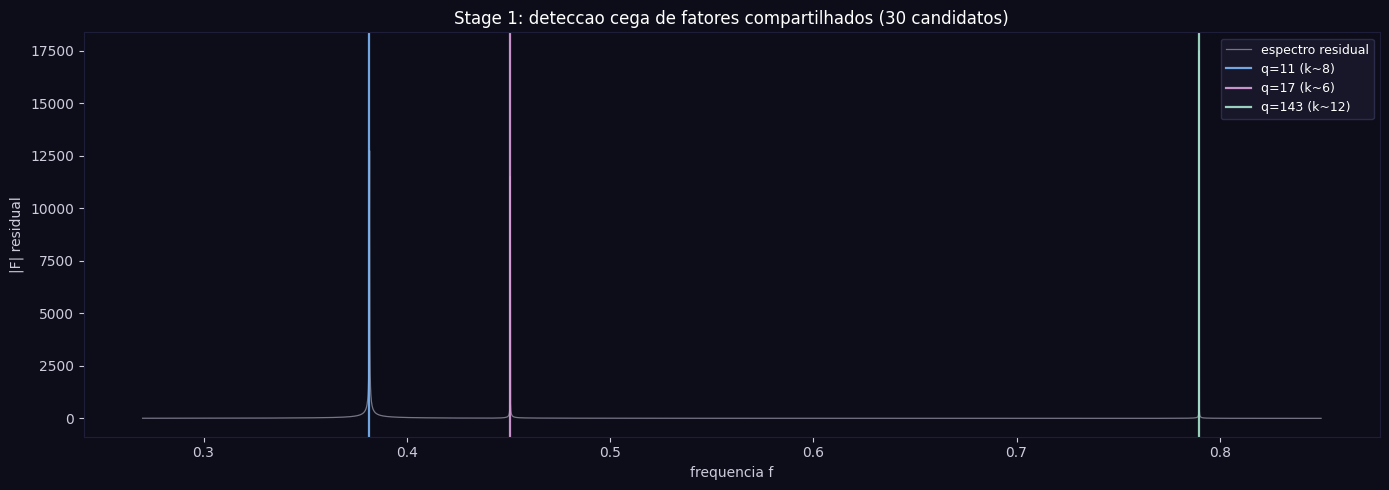

Figura salva: detector_d_stage1.png


In [4]:
# Visualizacao Stage 1: espectro completo + marcadores dos picos
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

f_lo, f_hi = 0.27, 0.85
mask = (freqs > f_lo) & (freqs < f_hi)
ax.plot(freqs[mask], F1[mask], color='#888899', lw=0.9, alpha=0.85, label='espectro residual')

cores_achados = {143:C_A, 11:C_B, 17:C_C}
for a in achados_s1:
    q = a['q']
    fq = math.log(q)/(2*math.pi)
    cor = cores_achados.get(q, C_S2)
    ax.axvline(fq, color=cor, lw=1.6, alpha=0.9,
               label=f'q={q} (k~{a["k_estimado"]})')

ax.set_xlabel('frequencia f', color=C_TEXT)
ax.set_ylabel('|F| residual', color=C_TEXT)
ax.set_title('Stage 1: deteccao cega de fatores compartilhados (30 candidatos)',
             color='white', fontsize=12)
ax.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=9)
ax.tick_params(colors=C_TEXT)
for s in ax.spines.values(): s.set_edgecolor(C_GRID)

plt.tight_layout()
plt.savefig('detector_d_stage1.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Figura salva: detector_d_stage1.png')


## 4. Reconstrução cega dos grupos

Com os cofatores detectados (143, 11, 17), o algoritmo reconstrói os grupos
testando cada candidato do lote contra cada cofator — ainda sem usar a estrutura real.


In [5]:
cofatores_detectados = [a['q'] for a in achados_s1]
print(f'Cofatores detectados no Stage 1: {cofatores_detectados}')
print()

grupos_reconstruidos = {q: [] for q in cofatores_detectados}
nao_classificados = []

for m in LOTE:
    cf = cofator(m, P1)
    if cf in grupos_reconstruidos:
        grupos_reconstruidos[cf].append(m)
    else:
        nao_classificados.append(m)

print('Grupos reconstruidos (cegos, a partir so dos cofatores detectados):')
for q, membros in grupos_reconstruidos.items():
    print(f'  cofator {q}: {len(membros)} candidatos -> {membros}')
print()
print(f'Nao classificados (decoys, sem fator compartilhado): {nao_classificados}')


Cofatores detectados no Stage 1: [11, 17, 143]

Grupos reconstruidos (cegos, a partir so dos cofatores detectados):
  cofator 11: 8 candidatos -> [22, 33, 44, 55, 66, 77, 88, 99]
  cofator 17: 6 candidatos -> [34, 51, 68, 85, 102, 119]
  cofator 143: 12 candidatos -> [286, 429, 572, 715, 858, 1001, 1144, 1287, 1430, 1716, 2002, 2145]

Nao classificados (decoys, sem fator compartilhado): [12, 18, 36, 60]


## 5. Stage 2 — crack do grupo composto

O único cofator composto detectado é 143. Aplicamos o Stage 2 (subtrair $\log(11)$,
o menor fator de 143) sobre o grupo reconstruído.


In [6]:
grupo_composto = [q for q in cofatores_detectados if not isprime(q)]
print(f'Cofatores compostos a resolver: {grupo_composto}')

resultados_s2 = {}
for q_comp in grupo_composto:
    membros = grupos_reconstruidos[q_comp]
    k = len(membros)

    p_menor = min(p for p in range(11, int(math.isqrt(q_comp))+2) if isprime(p) and q_comp % p == 0)
    q_novo  = q_comp // p_menor

    F2 = espectro(sinal_de(membros, lambda m: log_res(m, P1) - math.log(p_menor)))
    ai_novo = amp_iso_de(q_novo)
    a2 = amp_em_f(F2, math.log(q_novo)/(2*math.pi))
    ratio2 = a2 / ai_novo

    resultados_s2[q_comp] = {'p': p_menor, 'q_novo': q_novo, 'ratio': ratio2,
                             'F2': F2, 'k': k}
    print(f'  {q_comp} = {p_menor} x {q_novo}  ratio={ratio2:.5f}  previsto={k}  erro={abs(ratio2-k):.5f}')
    print(f'    -> {q_novo} primo: {isprime(q_novo)}')


Cofatores compostos a resolver: [143]
  143 = 11 x 13  ratio=12.00000  previsto=12  erro=0.00000
    -> 13 primo: True


## 6. Verificação contra estrutura real

In [7]:
print('=== Verificacao: classificacao do detector vs estrutura real ===')
print()

mapa_grupo_real = dict(zip(LOTE, LABELS_REAIS))
mapa_cofator_grupo = {143:'A', 11:'B', 17:'C'}

acertos = 0
print(f'{"m":>5}  {"grupo_real":>10}  {"cofator_detectado":>18}  {"grupo_predito":>14}  {"ok":>4}')
print('-'*60)
for m in LOTE:
    real = mapa_grupo_real[m]
    cf = cofator(m, P1)
    pred = mapa_cofator_grupo.get(cf, 'decoy')
    ok = '✓' if pred == real else '✗'
    if pred == real: acertos += 1
    print(f'{m:>5}  {real:>10}  {cf:>18}  {pred:>14}  {ok:>4}')

print()
print(f'Acertos: {acertos}/{len(LOTE)} ({100*acertos/len(LOTE):.1f}%)')
print()
print('Fatoracao prima completa (via Stage 1 + Stage 2):')
print(f'  Grupo A: cofator 143 = 11 x 13  ({len(GRUPO_A)} candidatos)')
print(f'  Grupo B: cofator 11 (primo)      ({len(GRUPO_B)} candidatos)')
print(f'  Grupo C: cofator 17 (primo)      ({len(GRUPO_C)} candidatos)')
print(f'  Decoys: sem fator compartilhado ({len(DECOYS)} candidatos)')


=== Verificacao: classificacao do detector vs estrutura real ===

    m  grupo_real   cofator_detectado   grupo_predito    ok
------------------------------------------------------------
  286           A                 143               A     ✓
  429           A                 143               A     ✓
  572           A                 143               A     ✓
  715           A                 143               A     ✓
  858           A                 143               A     ✓
 1001           A                 143               A     ✓
 1144           A                 143               A     ✓
 1287           A                 143               A     ✓
 1430           A                 143               A     ✓
 1716           A                 143               A     ✓
 2002           A                 143               A     ✓
 2145           A                 143               A     ✓
   22           B                  11               B     ✓
   33           B                

## 7. Comparação com MDC par-a-par

In [8]:
from math import gcd

k_total = len(LOTE)
total_pares = k_total*(k_total-1)//2

pares_mdc = []
for i in range(k_total):
    for j in range(i+1, k_total):
        g = gcd(LOTE[i], LOTE[j])
        if g > 7:
            pares_mdc.append((LOTE[i], LOTE[j], g))

fatores_mdc = Counter([p[2] for p in pares_mdc])
print(f'=== MDC par-a-par ({k_total} candidatos) ===')
print(f'Operacoes: {total_pares}')
print(f'Pares com fator comum > 7: {len(pares_mdc)}')
print()
print('Fatores encontrados via MDC (sem identificar a raiz prima diretamente):')
for f, cnt in sorted(fatores_mdc.items(), key=lambda x:-x[1])[:10]:
    tipo = 'primo' if isprime(f) else f'composto={dict(factorint(f))}'
    print(f'  {f:>4}: {cnt:>3} pares  [{tipo}]')

print()
print('=== Comparacao final ===')
n_fft = 2  # Stage 1 + Stage 2 do grupo A
print(f'{"metodo":<25} {"operacoes":>12} {"identifica primo direto":>25}')
print('-'*65)
print(f'{"MDC par-a-par":<25} {total_pares:>12} {"Nao (requer pos-fatoracao)":>25}')
print(f'{"Detector espectral":<25} {n_fft:>12} {"Sim (Stage 2)":>25}')
print()
print(f'Vantagem: {total_pares/n_fft:.0f}x menos operacoes')


=== MDC par-a-par (30 candidatos) ===
Operacoes: 435
Pares com fator comum > 7: 218

Fatores encontrados via MDC (sem identificar a raiz prima diretamente):
    11:  69 pares  [primo]
   143:  32 pares  [composto={11: 1, 13: 1}]
    22:  25 pares  [composto={2: 1, 11: 1}]
   286:  17 pares  [composto={2: 1, 11: 1, 13: 1}]
    33:  15 pares  [composto={3: 1, 11: 1}]
    17:  11 pares  [primo]
   429:   9 pares  [composto={3: 1, 11: 1, 13: 1}]
    44:   6 pares  [composto={2: 2, 11: 1}]
    12:   6 pares  [composto={2: 2, 3: 1}]
     9:   4 pares  [composto={3: 2}]

=== Comparacao final ===
metodo                       operacoes   identifica primo direto
-----------------------------------------------------------------
MDC par-a-par                      435 Nao (requer pos-fatoracao)
Detector espectral                   2             Sim (Stage 2)

Vantagem: 218x menos operacoes


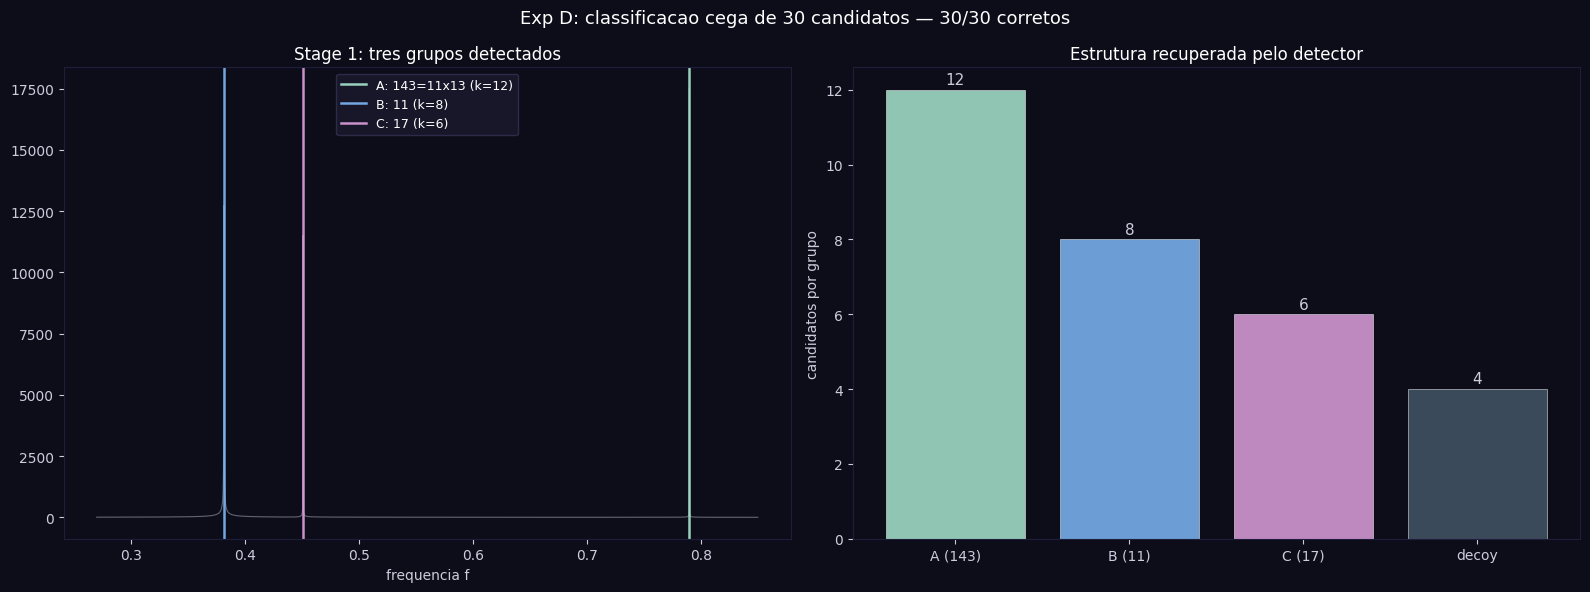

Figura salva: detector_d_classificacao.png


In [9]:
# Visualizacao final: classificacao completa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor(BG)
fig.suptitle(f'Exp D: classificacao cega de {len(LOTE)} candidatos — {acertos}/{len(LOTE)} corretos',
             color='white', fontsize=13)

# Painel 1: espectro com grupos coloridos
ax = axes[0]; ax.set_facecolor(BG)
mask = (freqs > 0.27) & (freqs < 0.85)
ax.plot(freqs[mask], F1[mask], color='#888899', lw=0.8, alpha=0.7)
for q, cor, lbl in [(143,C_A,'A: 143=11x13'),(11,C_B,'B: 11'),(17,C_C,'C: 17')]:
    fq = math.log(q)/(2*math.pi)
    k_est = round(amp_em_f(F1,fq)/amp_iso_de(q))
    ax.axvline(fq, color=cor, lw=1.8, alpha=0.9, label=f'{lbl} (k={k_est})')
ax.set_xlabel('frequencia f', color=C_TEXT)
ax.set_title('Stage 1: tres grupos detectados', color='white')
ax.legend(facecolor='#1A1A2E', edgecolor='#333355', labelcolor='white', fontsize=9)
ax.tick_params(colors=C_TEXT)
for s in ax.spines.values(): s.set_edgecolor(C_GRID)

# Painel 2: distribuicao de candidatos por grupo (real vs detectado)
ax2 = axes[1]; ax2.set_facecolor(BG)
grupos_nomes = ['A (143)', 'B (11)', 'C (17)', 'decoy']
tam_real = [len(GRUPO_A), len(GRUPO_B), len(GRUPO_C), len(DECOYS)]
cores_g = [C_A, C_B, C_C, C_DEC]
bars = ax2.bar(grupos_nomes, tam_real, color=cores_g, alpha=0.85, edgecolor='white', lw=0.4)
for i,v in enumerate(tam_real):
    ax2.text(i, v+0.15, str(v), ha='center', color=C_TEXT, fontsize=11)
ax2.set_ylabel('candidatos por grupo', color=C_TEXT)
ax2.set_title('Estrutura recuperada pelo detector', color='white')
ax2.tick_params(colors=C_TEXT)
for s in ax2.spines.values(): s.set_edgecolor(C_GRID)

plt.tight_layout()
plt.savefig('detector_d_classificacao.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Figura salva: detector_d_classificacao.png')


In [10]:
import zipfile, os
arquivos = ['detector_d_stage1.png', 'detector_d_classificacao.png']
with zipfile.ZipFile('detector_d_resultados.zip', 'w') as zf:
    for arq in arquivos:
        if os.path.exists(arq): zf.write(arq)
print('Pacote: detector_d_resultados.zip')
for arq in arquivos:
    print(f'  [{"OK" if os.path.exists(arq) else "FALTANDO"}] {arq}')


Pacote: detector_d_resultados.zip
  [OK] detector_d_stage1.png
  [OK] detector_d_classificacao.png
